In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report

In [15]:
RANDOM_STATE=24 # in production we set rs=None it is hard to change everyware
np.random.seed(RANDOM_STATE)
rng=np.random.default_rng(seed=RANDOM_STATE)
NOISE=0.2
EPOCHS=20001
ALPHA=0.1 #LEARNING RATE
TEST_SIZE=0.2
N_SAMPLES=1000
params={
    'legend.fontsize':'medium',
    'figure.figsize':(15,6),
    'axes.labelsize':'medium',
    'axes.titlesize':'medium',
    'xtick.labelsize':'medium',  
    'ytick.labelsize':'medium',  
    
}
plt.rcParams.update(params)
CMAP=plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid')

In [16]:
def plot_decision_boundary(
    model:dict,
    X_tr:np.ndarray,
    y_tr:np.ndarray,
    X_ts:np.ndarray,
    y_ts:np.ndarray
):
    fig, ax =plt.subplots()
    dm= 0.01
    margin= 10*dm
    X_min = min(X_tr[:, 0].min() - margin, X_ts[:, 0].min() - margin)
    X_max = max(X_tr[:, 0].max() + margin, X_ts[:, 0].max() + margin)
    y_min = min(X_tr[:, 1].min() - margin, X_ts[:, 1].min() - margin)
    y_max = max(X_tr[:, 1].max() + margin, X_ts[:, 1].max() + margin)

    xx, yy= np.meshgrid(np.arange(X_min, X_max, dm), 
                        np.arange(y_min, y_max, dm))
    XX= np.c_[xx.ravel(), yy.ravel()]
    Z= predict(model,XX).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=plt.cm.Paired, alpha=0.6)
    ax.scatter(X_tr[:,0], X_tr[:,1], c=y_tr, s=30, edgecolors='k', cmap=CMAP)
    ax.scatter(X_ts[:,0], X_ts[:,1], c=y_ts, s=30, marker='*', edgecolors='k', cmap=plt.cm.seismic)

    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.set_title('Decision Boundary')
    ax.legend()

In [17]:
X,y=datasets.make_moons(n_samples=N_SAMPLES,
                        shuffle=True,
                        noise=NOISE,
                        random_state=RANDOM_STATE
                       )
X[:5],y[:5]

(array([[ 0.90633951,  0.90267624],
        [-1.11536828,  0.75579289],
        [ 1.88769158,  0.4175967 ],
        [-0.93345034, -0.02299851],
        [-0.96872877,  0.06396285]]),
 array([0, 0, 1, 0, 0]))

In [18]:
y=pd.get_dummies(y).to_numpy()
y.shape

(1000, 2)

In [19]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=TEST_SIZE,
                                               random_state=RANDOM_STATE,
                                               stratify=y)

In [32]:
sns.scatterplot(X,hue=y)

ValueError: The following variable cannot be assigned with wide-form data: `hue`

In [21]:
def fn_sigmoid(z):
    return 1/(1+np.exp(-z))

In [22]:
def fn_activ(z: np.ndarray)->np.ndarray:
    return np.tanh(z)
def fn_activ_prime(z: np.ndarray)-> np.ndarray:
    return 1.0-np.tanh(z)**2

In [23]:
fn_activ(np.asarray([[-1,0,-1],[-np.inf,0,np.inf]]))

array([[-0.76159416,  0.        , -0.76159416],
       [-1.        ,  0.        ,  1.        ]])

In [24]:
def predict(model: dict, X_p: np.ndarray):
    W1, W2 = model['W1'], model['W2']
    # Ensure this extracts 'b2', not 'b1' a second time
    b1, b2 = model['b1'], model['b2'] 

    # Layer 1
    z1 = X_p.dot(W1) + b1 
    a1 = fn_activ(z1) 

    # Layer 2
    z2 = a1.dot(W2) + b2 
    a2 = fn_sigmoid(z2) 

    return a2 >= 0.5

In [25]:
def fn_calculate_loss(model: dict, X_l: np.ndarray, y_l: np.ndarray):
    '''
    model: Dictionary containing weights and bias
    X_l: input features
    y_l: Target
    '''
    m=X_l.shape[0]
    W1,W2=model['W1'], model['W2']
    b1,b2=model['b1'], model['b1']

    #Forward Propagation
    #Layer 1
    z1=X_l.dot(W1)+b1 #aggrigarion Function
    a1 =fn_activ(z1) #activation 

    #Layer 2
    z2=a1.dot(W2)+b2 #aggrigarion Function
    a2 =fn_sigmoid(z2) #activation 

    data_loss=-(y_l*np.log(a2)+(1-y_l)*np.log(1-a2)).sum()

    return data_loss/m # to average


In [26]:
def fn_build_model(
    nn_hdim: np.int64,
    X: np.ndarray,
    y: np.ndarray,
    alpha: np.float64=ALPHA,
    n_epochs:np.int64=EPOCHS
    )->dict:
    '''
    nn_hdim: Number of hidden units,
    X: Features,
    y: Labels,
    alpha: Learning Rate,
    n_epochs: number of passes through complete data for the Gradient decent
    '''
    m,nn_input_dim=X.shape
    nn_output_dim=y.shape[1]
    
    W1=rng.random((nn_input_dim, nn_hdim), dtype= np.float32)/np.sqrt(nn_input_dim)    
    W2=rng.random((nn_hdim, nn_output_dim), dtype= np.float32)/np.sqrt(nn_hdim)   

    b1=np.zeros((1,nn_hdim), dtype=np.float32)
    b2=np.zeros((1,nn_output_dim), dtype=np.float32)

    curr_loss=0
    loss, epoch=[], []

    for i in range(n_epochs):
        ## Froward Probagation
        #Layer1
        z1=X.dot(W1)+b1 #aggrigarion Function
        a1 =fn_activ(z1) #activation 

         #Layer 2
        z2=a1.dot(W2)+b2 #aggrigarion Function
        a2 =fn_sigmoid(z2) #activation 

        # Backprobagation 
        # Layer 2
        dz2 = a2 - y
        dw2 = (a1.T).dot(dz2)
        assert (W2.shape == dw2.shape), f'Shape -> W2: {w2.shape} | dw2: {dw2.shape}'

        db2 = np.sum(dz2, axis=0, keepdims=True)
        assert (b2.shape == db2.shape), f'Shape -> b2: {b2.shape} | db2: {db2.shape}'

        da1 = dz2.dot(W2.T)
        assert (a1.shape == da1.shape), f'Shape -> a1: {a1.shape} | da1: {da1.shape}'

        # Layer 1
        dz1 = da1 * fn_activ_prime(z1)
        
        dw1 = (X.T).dot(dz1)
        assert (W1.shape == dw1.shape), f'Shape -> W1: {W1.shape} | dw1: {dw1.shape}'

        db1 = np.sum(dz1, axis=0, keepdims=True)
        assert (b1.shape == db1.shape), f'Shape -> b1: {b1.shape} | db1: {db1.shape}'



        #Gradient updates
        W1 = W1 - alpha * (dw1 / m)
        W2 = W2 - alpha * (dw2 / m)
        b1 = b1 - alpha * (db1 / m)
        b2 = b2 - alpha * (db2 / m)

        model={'W1': W1, 'W2': W2, 'b1': b1, 'b2': b2 }
        
        if i % 100 == 0:
            curr_loss = fn_calculate_loss(model=model, X_l=X, y_l=y)
            loss.append(curr_loss)
            epoch.append(i)
            print(f'Epoch {i:3d}: Loss = {curr_loss:.4f}')

    loss_hist['epoch'] = epoch
    loss_hist['loss'] = loss
    
    return model

        

In [27]:
loss_hist = {}
y_train = y_train.reshape(-1,1)
model = fn_build_model(4, X_train, y_train)

ValueError: operands could not be broadcast together with shapes (800,1) (1600,1) 

In [28]:
df_hist = pd.DataFrame(loss_hist, columns=['epoch', 'loss'])
df_hist.head()

,epoch,loss


<Axes: xlabel='epoch', ylabel='loss'>

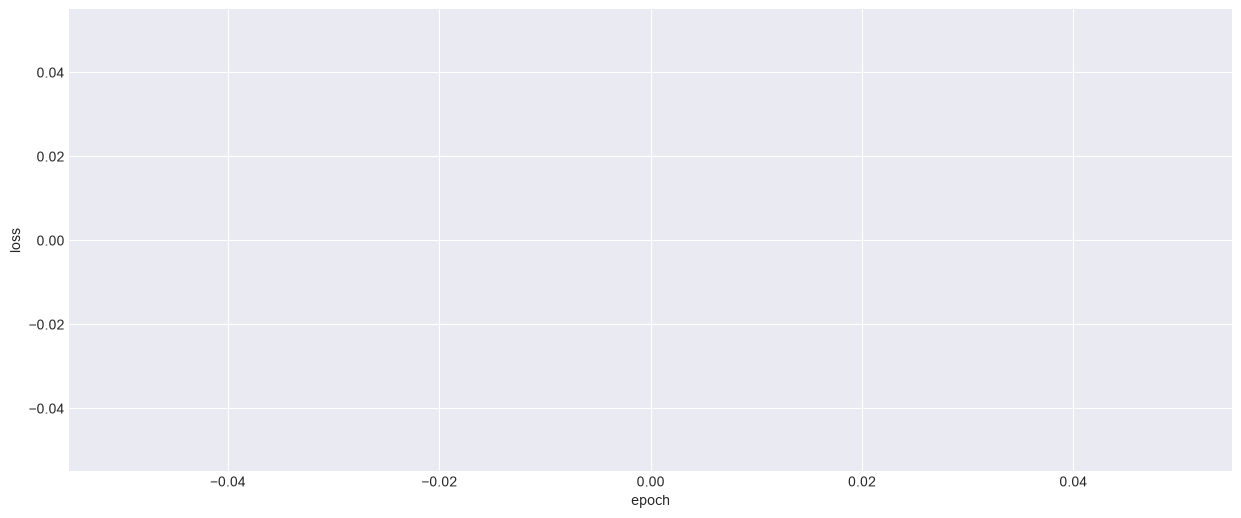

In [29]:
sns.lineplot(df_hist,x='epoch',y='loss')

In [30]:
y_pred = predict(model=model, X_p=X_train)
accuracy = accuracy_score(y_train, y_pred)
print(f"Accuracy: {accuracy:.4f}")

NameError: name 'model' is not defined

In [31]:
cm= confusion_matrix(y_train,y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=[0,1])
fig, ax= plt.subplots(figsize=(4,4))
disp.plot(ax=ax, cmap='Blues',colorbar=False)
plt.grid(False)

NameError: name 'y_pred' is not defined

In [ ]:
plot_decision_boundary(model,X_train,y_train,X_test,y_test)
